# 01 | Exploratory Data Analysis and Visualization

## Egyptian House Price Prediction

This notebook explores the original Egyptian property-listings dataset. The target is **Price** and the task is cross-sectional regression. The source CSV is preserved unchanged; all cleaning below is performed on an in-memory analysis copy.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("data/original_dataset.csv")
raw = pd.read_csv(DATA_PATH)
df = raw.copy()

## 1. Dataset overview

In [2]:
display(df.head())
display(df.tail())
print("Dataset shape:", df.shape)
display(df.dtypes.rename("Data type").to_frame())
display(df.describe(include="all").T)

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
27356,Town House,890000,3,2,240,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,North Coast
27357,Town House,4000000,4,3,218,Unknown,Unknown,Unknown,Cash or Installment,Unknown,Finished,New Cairo - El Tagamoa
27358,Twin House,13800000,3,4,308,No,Unknown,Cairo Festival City,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa
27359,Stand Alone Villa,35000000,4,4,478,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Finished,Mokattam
27360,Stand Alone Villa,4800000,5,5,NaN,No,Unknown,Unknown,Cash,Unknown,Finished,Sheikh Zayed


Dataset shape: (27361, 12)


,Data type
Type,object
Price,object
Bedrooms,object
Bathrooms,object
Area,object
Furnished,object
Level,object
Compound,object
Payment_Option,object
Delivery_Date,object


,count,unique,top,freq
Type,27179,11,Apartment,8341
Price,27302,4180,3000000,311
Bedrooms,26938,12,3,11677
Bathrooms,26988,12,2,9098
Area,26824,785,120,661
Furnished,27267,3,No,16447
Level,27284,14,Unknown,10387
Compound,27219,559,Unknown,11013
Payment_Option,27115,4,Cash or Installment,10752
Delivery_Date,27258,10,Ready to move,12094


## 2. Feature groups and data quality

In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)
quality = pd.DataFrame({"Missing values": df.isna().sum(), "Missing %": (df.isna().mean() * 100).round(2), "Unique values": df.nunique(dropna=True)})
display(quality.sort_values("Missing values", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))

Numerical columns: []
Categorical columns: ['Type', 'Price', 'Bedrooms', 'Bathrooms', 'Area', 'Furnished', 'Level', 'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City']


,Missing values,Missing %,Unique values
Area,537,1.96,785
Bedrooms,423,1.55,12
Bathrooms,373,1.36,12
Payment_Option,246,0.90,4
Type,182,0.67,11
Compound,142,0.52,559
Delivery_Date,103,0.38,10
Furnished,94,0.34,3
Level,77,0.28,14
Delivery_Term,75,0.27,5


Exact duplicate rows: 1909


## 3. Analysis cleaning

The source stores numeric-looking values as text. `Unknown` and the phone-number placeholder are treated as missing for analysis. `Ground` is mapped to floor level 0, `10+` to 10, and `Highest` is left missing because it is not a precise numeric floor. These transformations do not alter the original CSV.

In [4]:
eda = df.copy()
for column in eda.columns:
    if eda[column].dtype == "object":
        eda[column] = eda[column].astype("string").str.strip()
        eda[column] = eda[column].replace(r"^Unknown$", pd.NA, regex=True)
eda["City"] = eda["City"].replace("(View phone number)", pd.NA)
for column in ["Price", "Bedrooms", "Bathrooms", "Area"]:
    eda[column] = pd.to_numeric(eda[column].astype("string").str.replace(",", "", regex=False), errors="coerce")
eda["Level"] = eda["Level"].replace({"Ground": "0", "10+": "10", "Highest": pd.NA})
eda["Level"] = pd.to_numeric(eda["Level"], errors="coerce")
print("Analysis-copy shape:", eda.shape)
print("Rows with missing target:", int(eda["Price"].isna().sum()))
print("Rows after excluding missing target and exact duplicates:", int(eda.drop_duplicates().dropna(subset=["Price"]).shape[0]))

Analysis-copy shape: (27361, 12)
Rows with missing target: 96


Rows after excluding missing target and exact duplicates: 25404


## 4. Target distribution and outliers

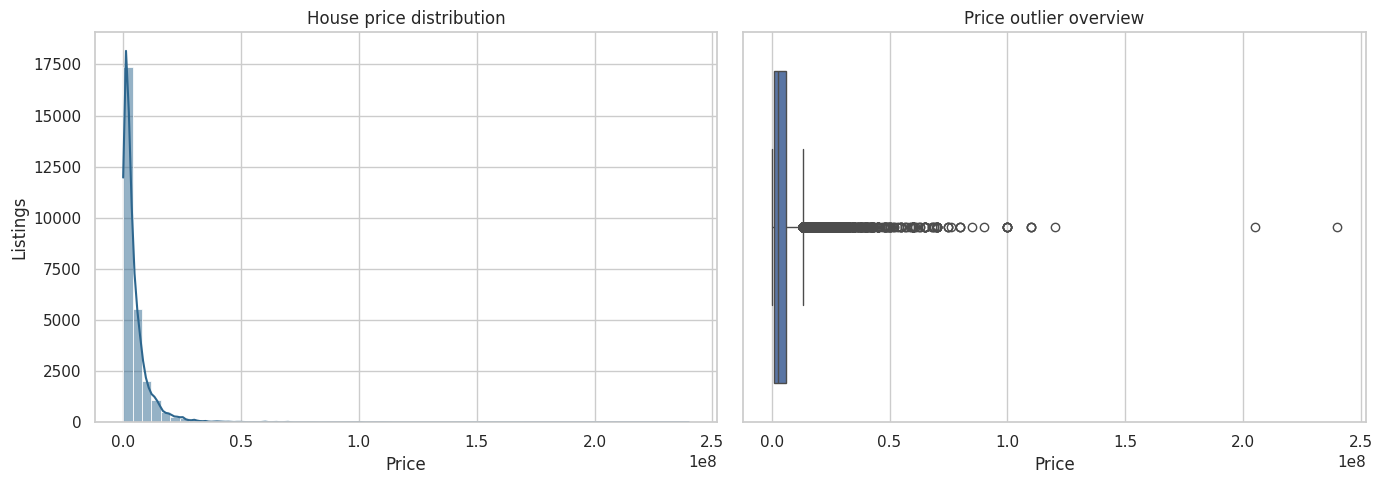

count           27265.0
mean     4762410.925362
std       6770022.25623
min             30000.0
1%             155000.0
25%           1150000.0
50%           2731000.0
75%           5990000.0
95%          15500000.0
99%          30000000.0
max         240000000.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(eda["Price"].dropna(), bins=60, kde=True, color="#2d668e", ax=axes[0])
axes[0].set(title="House price distribution", xlabel="Price", ylabel="Listings")
sns.boxplot(x=eda["Price"], ax=axes[1])
axes[1].set(title="Price outlier overview", xlabel="Price")
plt.tight_layout()
plt.show()
print(eda["Price"].describe(percentiles=[.01, .25, .5, .75, .95, .99]).to_string())

The target is right-skewed and spans a wide price range. High-price listings may be genuine luxury properties, so they are not removed automatically. Absolute-error metrics should be read in the target currency scale, and large residuals may be concentrated among expensive properties.

## 5. Numerical distributions and correlations

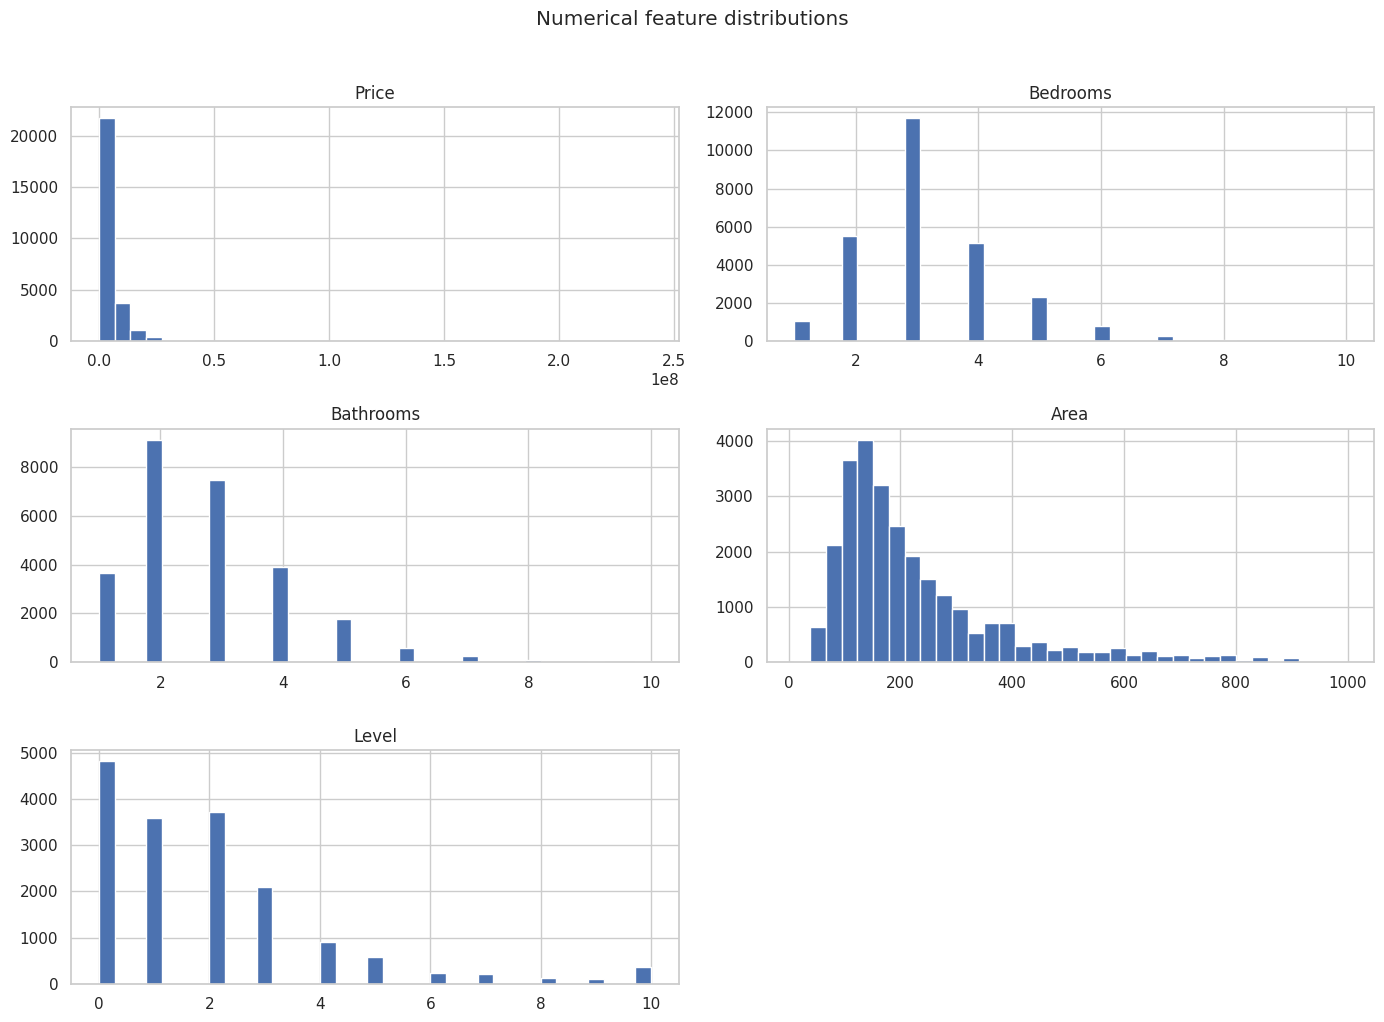

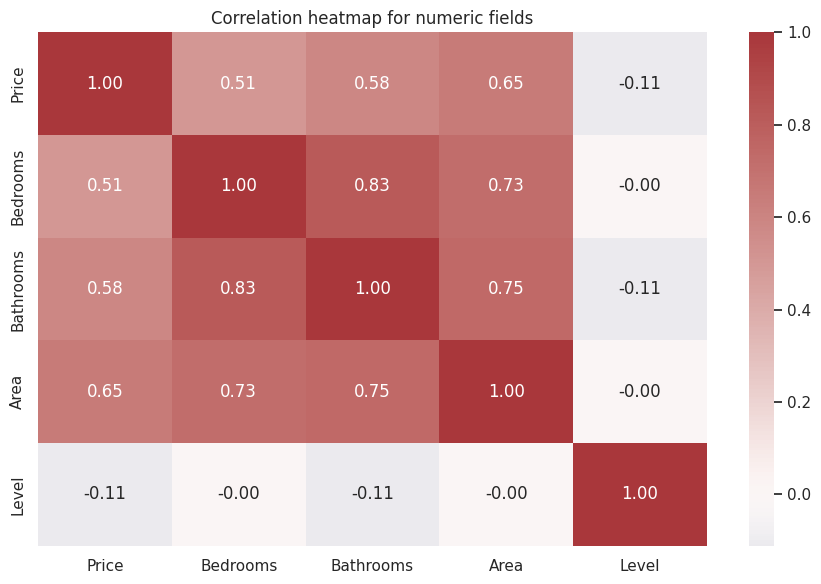

In [6]:
numeric_eda = eda.select_dtypes(include=np.number)
axes = numeric_eda.hist(figsize=(14, 10), bins=35, edgecolor="white")
plt.suptitle("Numerical feature distributions", y=1.02)
plt.tight_layout()
plt.show()
if numeric_eda.shape[1] > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_eda.corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
    plt.title("Correlation heatmap for numeric fields")
    plt.tight_layout()
    plt.show()

## 6. Feature relationships with price

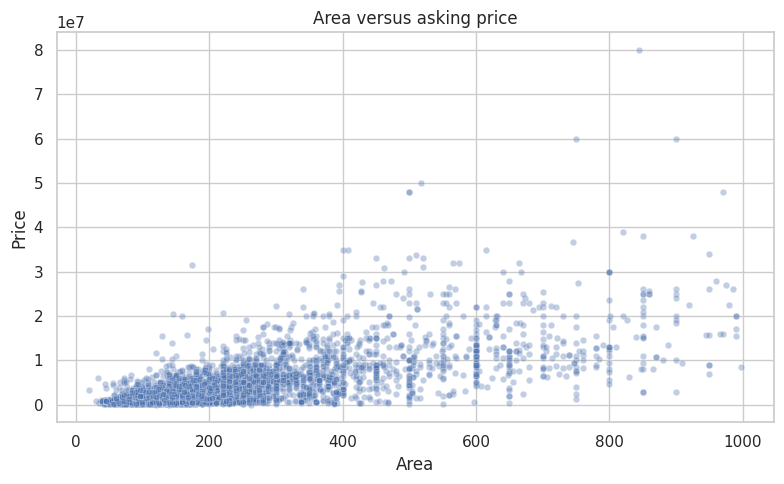

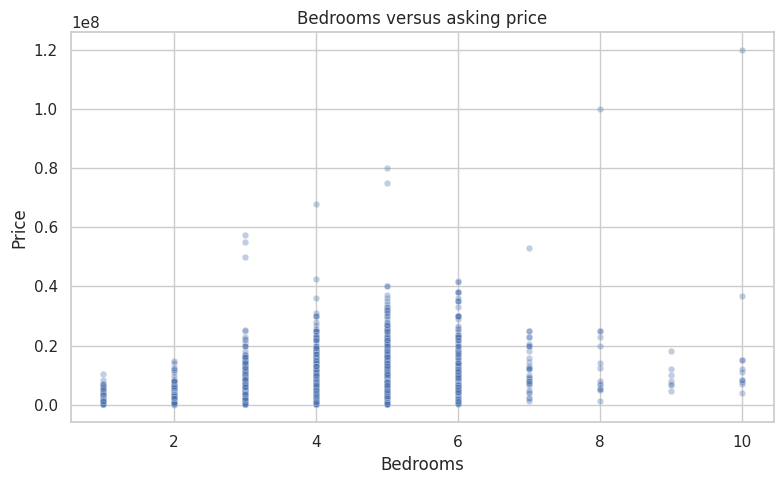

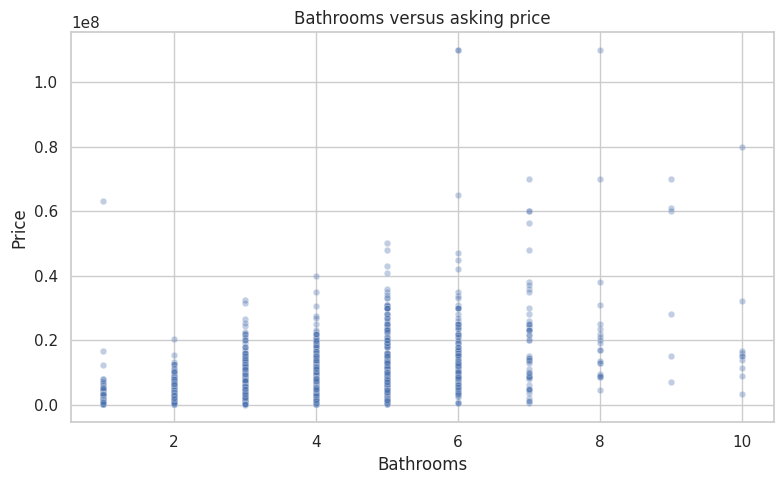

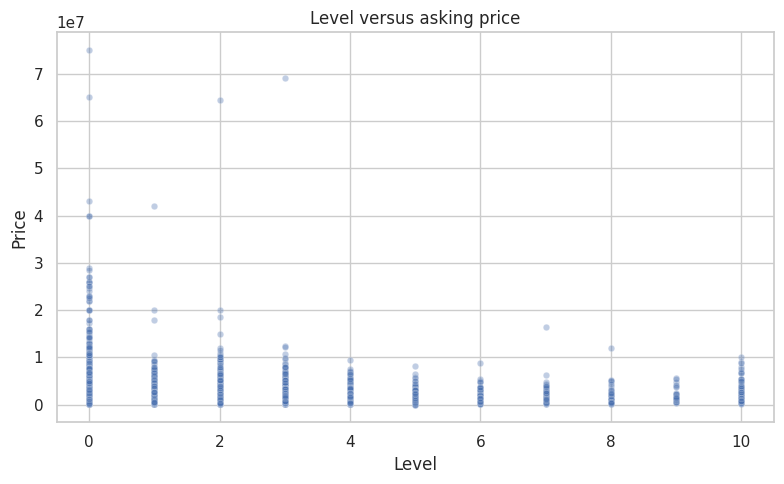

In [7]:
for column in ["Area", "Bedrooms", "Bathrooms", "Level"]:
    if column in eda.columns:
        pair = eda[[column, "Price"]].dropna()
        if len(pair) > 5000:
            pair = pair.sample(5000, random_state=42)
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=pair, x=column, y="Price", alpha=.35, s=22)
        plt.title(f"{column} versus asking price")
        plt.tight_layout()
        plt.show()

## 7. Categorical patterns

/tmp/ipykernel_534/3589275668.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  summary = summary.query("Listings >= 30").sort_values("Median_Price", ascending=False).head(15)


,Listings,Median_Price
City,,
Gouna,30,9000000.0
West Somid,42,7000000.0
Rehab City,674,5500000.0
Shorouk City,802,5250000.0
Sheikh Zayed,2396,5000000.0
New Cairo - El Tagamoa,6755,4000000.0
Borg al-Arab,131,3500000.0
Madinaty,1582,3150000.0
Moharam Bik,34,3147500.0


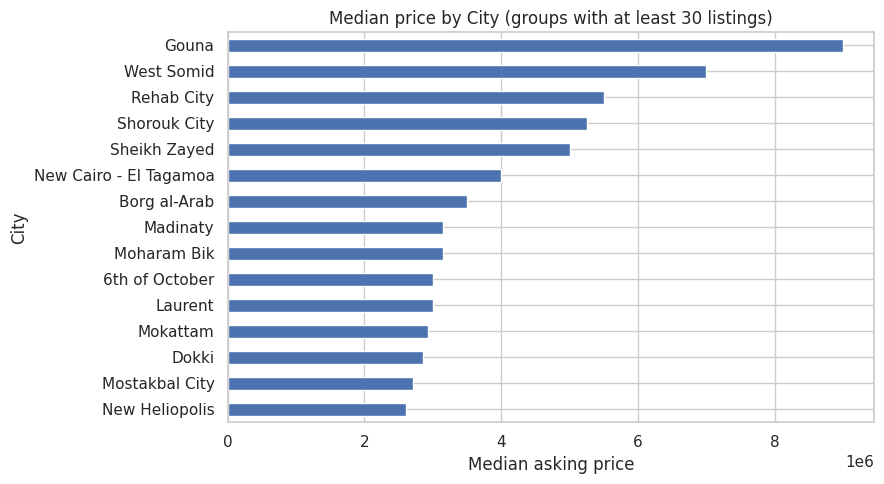

/tmp/ipykernel_534/3589275668.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  summary = summary.query("Listings >= 30").sort_values("Median_Price", ascending=False).head(15)


,Listings,Median_Price
Type,,
Stand Alone Villa,4620,9747750.0
Standalone Villa,608,9000000.0
Twin House,1787,7000000.0
Town House,3069,4931760.0
Twin house,483,4790983.0
Penthouse,523,3236000.0
Duplex,851,3200000.0
Chalet,6593,1950000.0
Apartment,8328,1650000.0


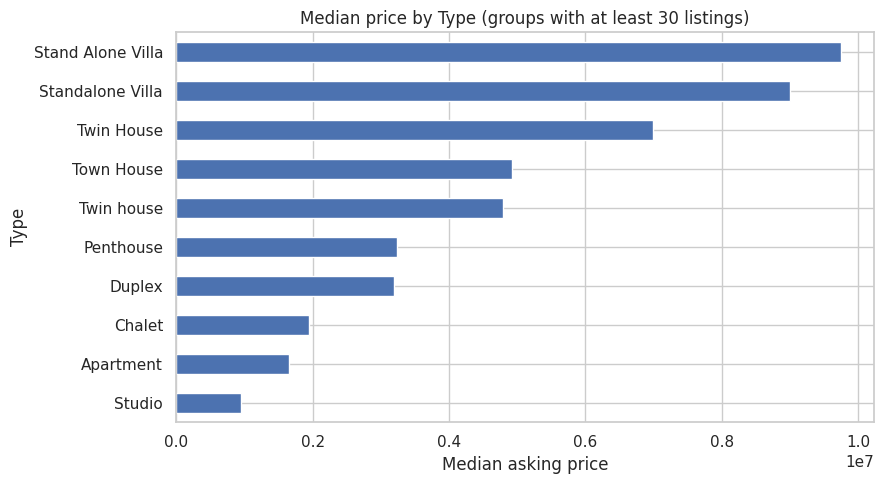

/tmp/ipykernel_534/3589275668.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  summary = summary.query("Listings >= 30").sort_values("Median_Price", ascending=False).head(15)


,Listings,Median_Price
Furnished,,
Yes,2319,3286206.0
No,16438,2860000.0


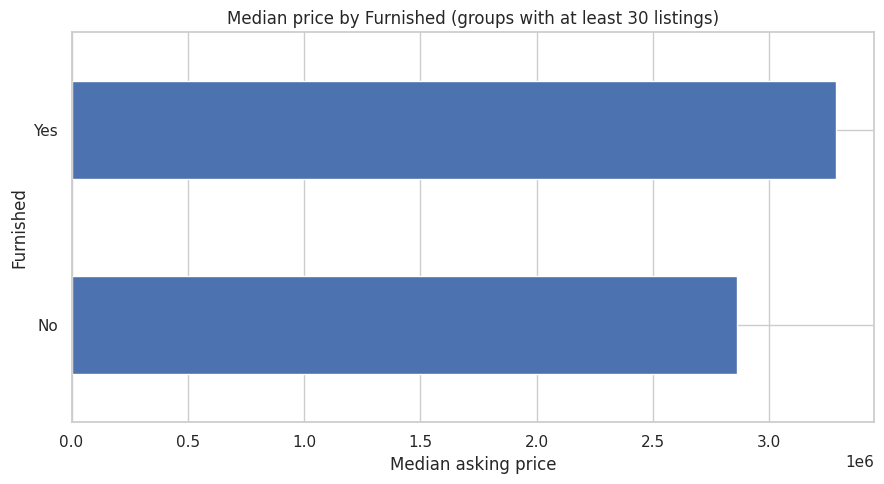

/tmp/ipykernel_534/3589275668.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  summary = summary.query("Listings >= 30").sort_values("Median_Price", ascending=False).head(15)


,Listings,Median_Price
Delivery_Term,,
Not Finished,1842,4500000.0
Core & Shell,923,4000000.0
Semi Finished,5461,3200000.0
Finished,14327,2600000.0


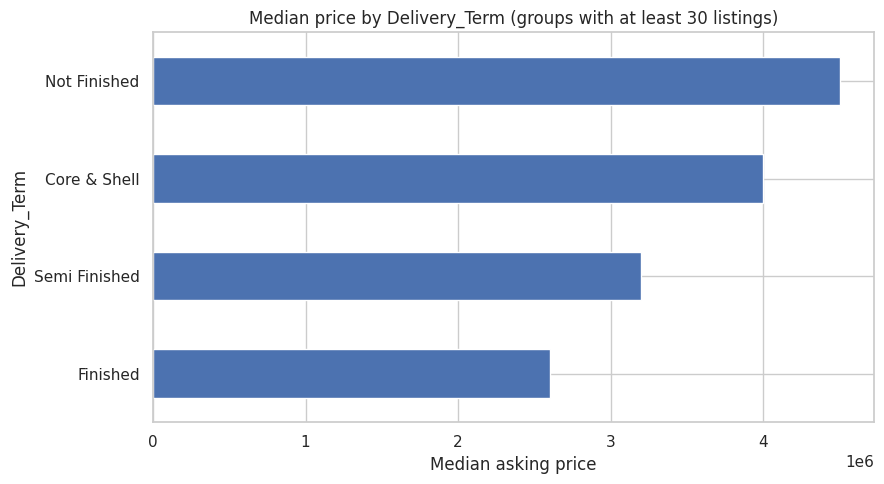

In [8]:
for column in ["City", "Type", "Furnished", "Delivery_Term"]:
    summary = eda.dropna(subset=[column, "Price"]).groupby(column)["Price"].agg(Listings="size", Median_Price="median")
    summary = summary.query("Listings >= 30").sort_values("Median_Price", ascending=False).head(15)
    display(summary)
    if not summary.empty:
        ax = summary["Median_Price"].sort_values().plot(kind="barh", figsize=(9, 5), title=f"Median price by {column} (groups with at least 30 listings)")
        ax.set_xlabel("Median asking price")
        plt.tight_layout()
        plt.show()

## 8. EDA conclusions

In [9]:
eda_summary = {
    "source_rows": int(raw.shape[0]),
    "source_columns": int(raw.shape[1]),
    "source_duplicates": int(raw.duplicated().sum()),
    "missing_price": int(pd.to_numeric(raw["Price"], errors="coerce").isna().sum()),
    "price_min": float(eda["Price"].min()),
    "price_median": float(eda["Price"].median()),
    "price_max": float(eda["Price"].max()),
    "city_placeholder_rows": int(raw["City"].eq("(View phone number)").sum())
}
display(pd.Series(eda_summary, name="Value").to_frame())

,Value
source_rows,27361.0
source_columns,12.0
source_duplicates,1909.0
missing_price,96.0
price_min,30000.0
price_median,2731000.0
price_max,240000000.0
city_placeholder_rows,61.0


### Main observations

- The dataset contains 27,361 listing rows and 12 columns; `Price` is the regression target.
- The source fields are stored as text, including numeric-looking variables, so explicit parsing is required.
- Missing/placeholder values and duplicate records require attention in the modeling copy.
- `Compound` and `City` are high-cardinality categorical features; unknown categories must be handled safely.
- The price distribution is strongly right-skewed. Genuine high-value observations are retained rather than removed solely because they are statistical outliers.
- This is a standard tabular regression task, not a time-series forecasting task.